# 05 — Cross-cohort analyses: the article's figures

Figure 3 and Supplementary Figs. Sa–Sc for **one state set**, chosen in the next cell. No split by
rest and movie here: every person over all their scans, rest counted as one more task.

* **Figure 3.** Top: every cohort (occupancy, p(j | i), dynamic metrics). Bottom left: the
  reference transition graph (the cohorts' mean, each cohort once). Bottom right: how much each
  property depends on the task — ω² of task within cohort, every task of every cohort
  (< 0.01 stable, 0.01–0.06 moderate, ≥ 0.06 task-dependent), with P(tier) from the bootstrap.
* **Sa–Sc.** Task by task (rest included): dynamic metrics, occupancy, transitions.

In [1]:
import sys
from pathlib import Path

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))

# every figure of a "# Plot N.k" / "# Figure N" cell is written to notebooks/figures/05/ (N_k.png), overwritten each run
from fmri_decomposition.figures import autosave
autosave.enable(REPO / "notebooks" / "figures" / "05")

from fmri_decomposition.unsupervised_model import cohort_tables as ct
from fmri_decomposition.figures import cohorts as cp

# ---- THE STATE SET: any atlas x window x clusterer stage 4b wrote (listed below)
ATLAS    = "yeo7"                   # the final model
WINDOW_S = -1
STATES   = "ThresholdCluster_umap3_8"          # e.g. "HMM2_pca3_8", "ThresholdCluster_umap3_8", "MeanShift_umap3_3"

# ---- panel C: data balance. "time" = every cohort the same HOURS of scan per draw (whole scans,
# pooled transition counts): people and stimulus duration balanced together. None = cohort means.
BALANCE  = "time"
HOURS    = 10
VERSUS   = "mean"                  # C: each cohort vs the mean of the others; "pairs" = every pair
N_BOOT   = 200                     # draws for panel C, bootstrap over people for panel D
PVALUE   = "stars"                 # Figure 3C confidence column: None, "exact" or "stars"; marker hollow when P(tier) < .95
TEST     = "tier"                  # "tier": P(tier), share of bootstrap |d| in the observed tier (* ≥.90, ** ≥.95, *** ≥.99);
                                    # "difference" (paired t), "tost" (equivalence ±0.2 SD), "both", "all"
COMBINE  = "random"                # "mixed": one mixed model, task share of variance; or ω² per cohort combined: "random", "fixed", "equal"
GUIDES   = True                    # Figure 3 task x person: dashed lines at (.01, .06) with True, or a tuple; None = none
SAVE_DIR = None                    # e.g. "figures/14": PNG + SVG of every figure

cfg = ct.Settings(
    space=dict(atlas=ATLAS, window_s=WINDOW_S, states=STATES),
    entropy_estimator="miller_madow",
    distinct_minutes="min",   # distinct transitions rarefied to the shortest scan (None = as stored)
    cohorts={"ds002837": dict(dirs=["ds002837"], role="train"),
             "cneuromod": dict(dirs=["cneuromod"], role="train"),
             "camcan": dict(dirs=["camcan", "camcan_rest"], role="projected"),
             "hcp7t_fix": dict(dirs=["hcp7t_fix"], role="projected")},
    rest_pattern=r"rest\d*",          # Rest, REST1..4 (HCP); every other task is movie
    alpha=0.10,                        # BH-FDR (A.2, films)
    fc_task=1.0, fc_dyn=0.25,          # A.2: |log2FC| for the graph and the dynamics
    edge_top=12,                       # A.1/A.2: strongest arrows drawn
    sesoi_d=0.2,
    save_dir=SAVE_DIR,
)
sets = ct.available_sets(cfg.root, cfg.cohorts, cfg.modelling_version)
print(f"{len(sets)} state sets have every cohort; at {ATLAS}, {WINDOW_S:g} s:")
print(", ".join(sets[(sets.atlas == ATLAS) & (sets.window_s.astype(float) == WINDOW_S)]["states"]))
co = ct.Cohorts(cfg)
co.tasks()
# ---- how the figures name the states: "number" (S3) | "name" | "both" (S3 · name); the names come
# from notebook 04 (state_names), per state set
STATE_LABELS = "name"
from fmri_decomposition.figures import state_names as sn
sn.use_for(cfg.root, ATLAS, WINDOW_S, STATES, cfg.modelling_version, mode=STATE_LABELS)

autosave: figures of '# Plot N.k' / '# Figure N' cells -> /project/6008063/tamires/DecomposingfMRI/notebooks/figures/05
282 state sets have every cohort; at yeo7, -1 s:
HMM1_pca3_10, HMM1_pca3_27, HMM1_pca3_8, HMM1_raw7_10, HMM1_raw7_27, HMM1_raw7_8, HMM1_umap3_10, HMM1_umap3_27, HMM1_umap3_8, HMM2_pca3_10, HMM2_pca3_27, HMM2_pca3_8, HMM2_raw7_10, HMM2_raw7_27, HMM2_raw7_8, HMM2_umap3_10, HMM2_umap3_27, HMM2_umap3_8, MeanShift_pca3_21, MeanShift_umap3_4, ThresholdCluster_pca3_27, ThresholdCluster_pca3_8, ThresholdCluster_umap3_27, ThresholdCluster_umap3_8
state labels: name · S0 Social Cognition, S1 Language & Music, S2 Cognitive Attention, S3 Somethesis & Action Execution, S4 Explicity Memory & Reasoning, S5 Emotion, S6 Vision, S7 Somethesis & Soma Cognition


{0: 'Social Cognition',
 1: 'Language & Music',
 2: 'Cognitive Attention',
 3: 'Somethesis & Action Execution',
 4: 'Explicity Memory & Reasoning',
 5: 'Emotion',
 6: 'Vision',
 7: 'Somethesis & Soma Cognition'}

## Figure 3

Every person over all their scans (all tasks, rest included). Top, every cohort; bottom left, the
reference graph (the cohorts' mean, each cohort once); bottom right, ω² of task within cohort.

#### Plot 5.0 — Figure 3 (bottom left: VPC task × VPC person)


mixed models read from /project/6008063/tamires/DecomposingfMRI/outputs/modelling/version=v0/unsupervised_model/mixed_model/atlas=yeo7/window_s=-1/states=ThresholdCluster_umap3_8


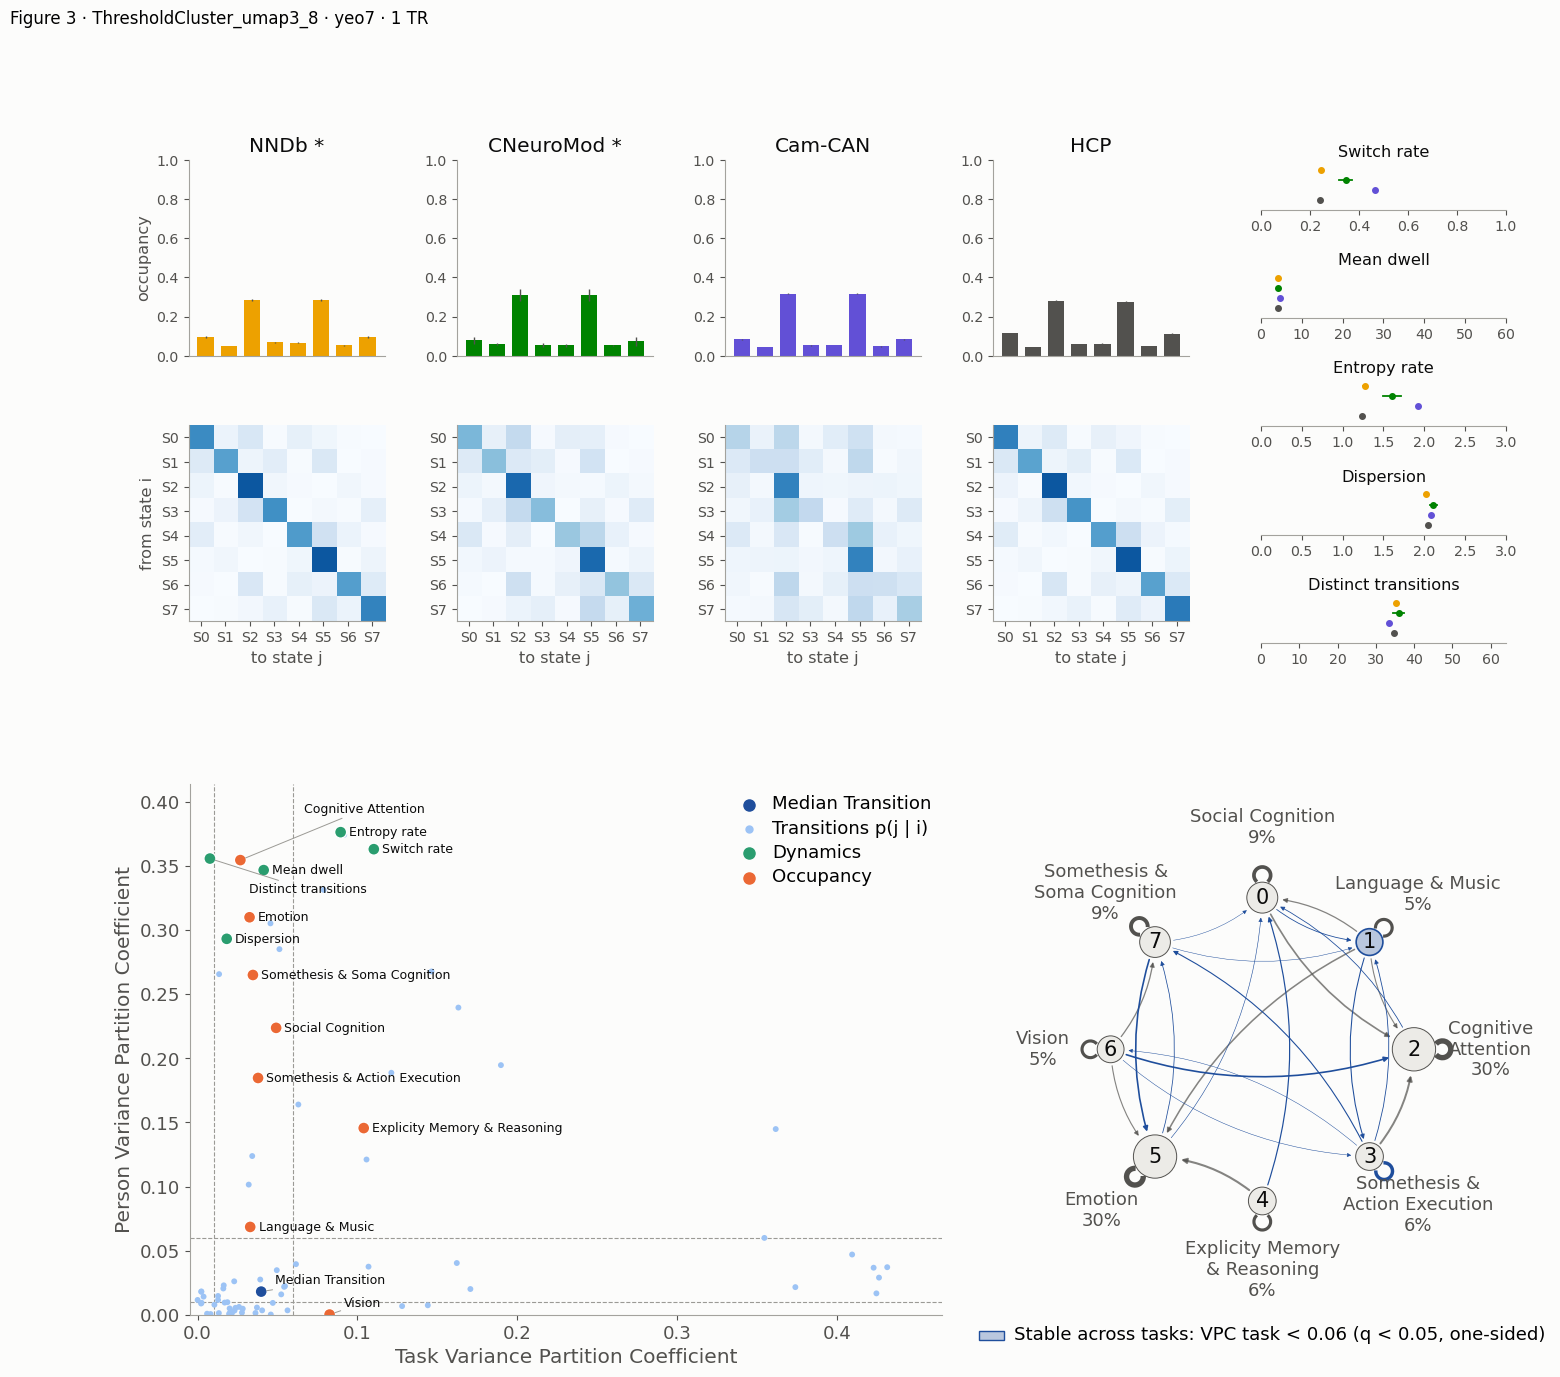

In [2]:
# Plot 5.0
SAVE_AS = None    # None = "5_0" -> notebooks/figures/05/5_0.png; to keep another version: SAVE_AS = "5_0_version2"
# the mixed models: read from outputs/.../unsupervised_model/mixed_model when slurm/mixed_model.sbatch
# has fitted them (slurm/mixed_model.sbatch has fitted every state set)
vp, vp_cells = ct.mixed_tables(co, fit_missing=False)   # read, never refit here
st = vp if COMBINE == "mixed" else co.task_variation(n_boot=N_BOOT, combine=COMBINE)
TRANSITIONS = "median"   # VPC panel: "structure" (one model of the transition structure) | "median" | "average" (of the p(j | i)) | "both"
DIAGRAM = "stable"   # "stable": diagram of Plot 5.0e (stable across tasks, VPC task < .06, q < .05, in blue) | "original"
cp.fig_figure3(co, vp, st_transitions=vp_cells, guides=GUIDES, transitions=TRANSITIONS, diagram=DIAGRAM);   # bottom left: VPC task x VPC person

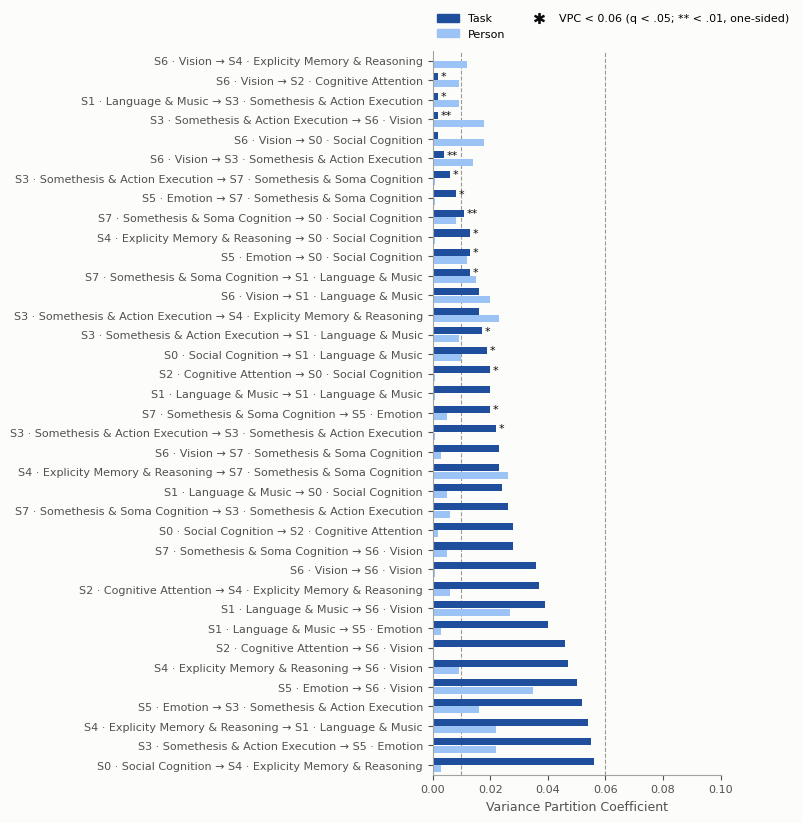

In [3]:
# Plot 5.0d
SAVE_AS = None    # None = "5_0d" -> notebooks/figures/05/5_0d.png; to keep another version: SAVE_AS = "5_0d_version2"
# the table behind the bars (built here, not shown): points of Plot 5.0 inside the guides
# VPC task and VPC person, each with its 95% CI and P(tier) (probability that the VPC lies in its own band)
SHOW     = "both"     # "both" (task and person) | "task" | "person": the bars drawn AND the shares INSIDE filters on
INSIDE   = True       # True: the SHOW share(s) under the upper guide (1 or 2 dimensions); False: every point
SORT_BY  = "task"     # order by the P(tier) of "task" or "person" (most certain first)
FAMILY   = "all"      # "all" | "occupancy" | "dynamics" | "transitions"
guide_tab = cp.guide_table(co, vp, st_transitions=vp_cells, guides=GUIDES, inside=INSIDE, sort_by=SORT_BY,
                           family_of=FAMILY, show=SHOW)

# the table as bars: VPC task and VPC person of each element; * / ** = the share is significantly under the
# upper guide (DOT = "below": stable) or over the lower ("above"), one-sided, q < .05 / .01
ORDER = ("task", "person")    # sort by VPC task then person; ("person", "task") the other way
DOT   = "below"               # "below": VPC < .06 (small, stable) | "above": VPC > .01 (not negligible)
USE_Q = True                  # FDR q-values (False: raw p)
LABELS = "both"               # states in the element names: "both" (S3 · name) | "number" (S3) | "name"
MAX_ELEMENTS = None           # draw only the first N rows of ORDER (None = all)
SHOW_CI = False               # the 95% interval of each VPC, where the model gave one
MARKED = "none"               # keep only rows with: "*" (q < .05) | "**" (q < .01) | "none" (all)
STARS = "two"                 # "two" (* and **) | "one" (* only) | "none"
cp.fig_guide_bars(co, guide_tab, order=ORDER, dot=DOT, use_q=USE_Q, guides=GUIDES, labels=LABELS,
                  max_elements=MAX_ELEMENTS, ci=SHOW_CI, stars=STARS, show=SHOW, marked=MARKED, name="vpc_bars");

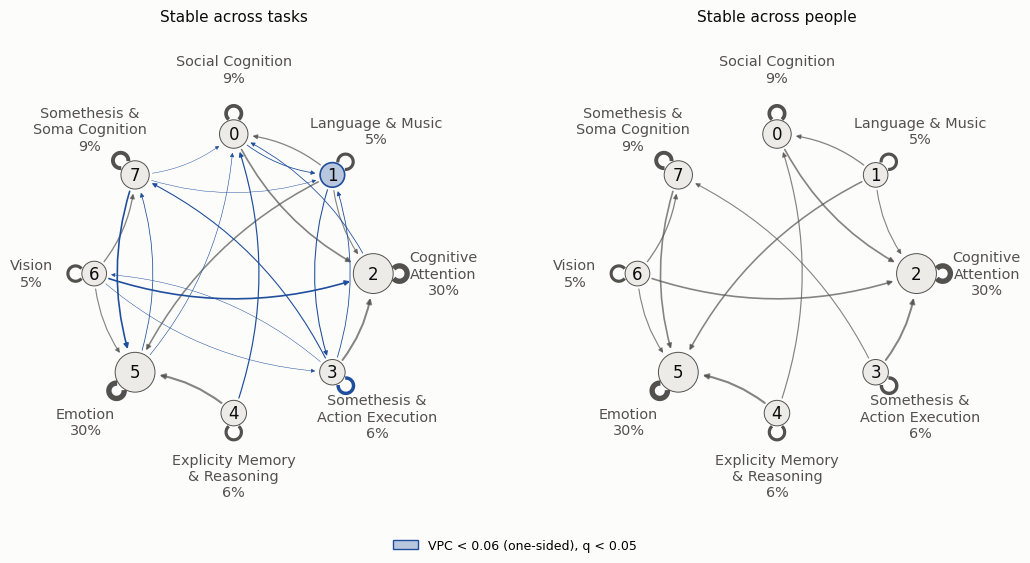

In [4]:
# Plot 5.0e
SAVE_AS = None    # None = "5_0e" -> notebooks/figures/05/5_0e.png; to keep another version: SAVE_AS = "5_0e_version2"
# Figure 3's diagram twice: left = stable across tasks, right = stable across people; in blue the
# transitions / occupancies that pass the tests (every element tested: the table without INSIDE)
LEVEL = .05       # .05: the * elements | .01: the ** ones; DOT and USE_Q as in Plot 5.0d
all_tab = cp.guide_table(co, vp, st_transitions=vp_cells, guides=GUIDES, inside=False)
cp.fig_stable_diagrams(co, all_tab, use_q=USE_Q, dot=DOT, guides=GUIDES, level=LEVEL, name="stable_diagrams");

#### Plot 5.0b — Figure 3 with the mixed model without the cohort term

The same figure, the VPC panel from `value ~ 1 + (1 | task) + (1 | person)` instead of `value ~ C(cohort) + (1 | task) + (1 | person)`. Every task belongs to one cohort (Cam-CAN's Rest and HCP's REST1 are different tasks), so without the cohort effect the differences between cohorts are carried by the task component: VPC task is then the share of tasks and cohorts together. Its own cache (`mixed_model_nocohort/`), made by `sbatch slurm/mixed_model.sbatch -- --atlas yeo7 --window-s -1 --states 'ThresholdCluster_umap3_8' --no-cohort-term`.

mixed models read from /project/6008063/tamires/DecomposingfMRI/outputs/modelling/version=v0/unsupervised_model/mixed_model_nocohort/atlas=yeo7/window_s=-1/states=ThresholdCluster_umap3_8


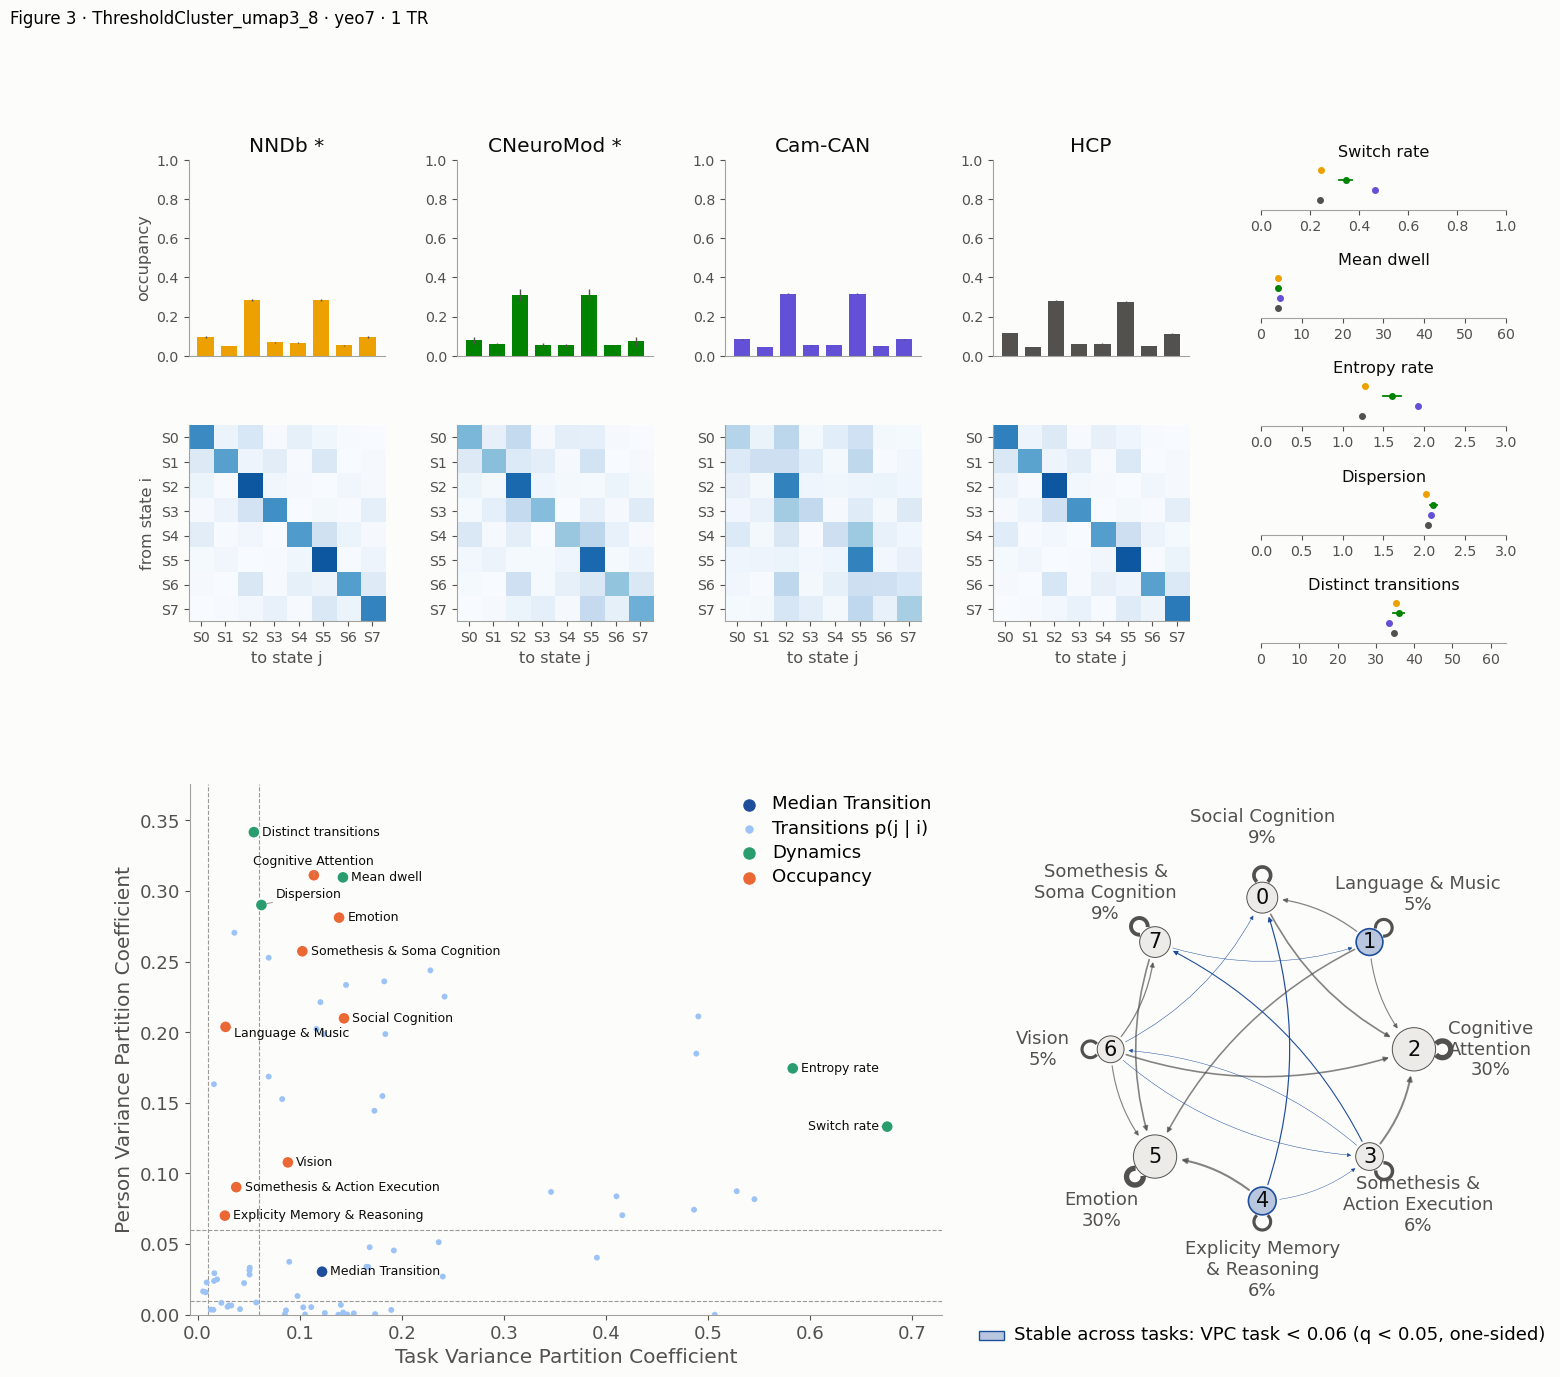

In [5]:
# Plot 5.0b
SAVE_AS = None    # None = "5_0b" -> notebooks/figures/05/5_0b.png; to keep another version: SAVE_AS = "5_0b_version2"
vp_nc, vp_cells_nc = ct.mixed_tables(co, fit_missing=False, cohort_term=False)   # read, never refit here
cp.fig_figure3(co, vp_nc, st_transitions=vp_cells_nc, guides=GUIDES, transitions=TRANSITIONS, diagram=DIAGRAM, name="figure3_nocohort");

#### Plot 5.0c — task × person within one cohort

The VPC panel of Figure 3 for `VPC_COHORT` alone: `value ~ 1 + (1 | task) + (1 | person)` fitted on that cohort's people only (with or without the cohort term is the same model here: one cohort). Not meaningful for NNDb, where every person saw one film (person and task cannot be told apart); CNeuroMod has 5 people, so its person share is imprecise. Its own cache, `sbatch slurm/mixed_model.sbatch -- --atlas yeo7 --window-s -1 --states 'ThresholdCluster_umap3_8' --cohort camcan hcp7t_fix cneuromod`.

mixed models read from /project/6008063/tamires/DecomposingfMRI/outputs/modelling/version=v0/unsupervised_model/mixed_model_cohort-camcan/atlas=yeo7/window_s=-1/states=ThresholdCluster_umap3_8


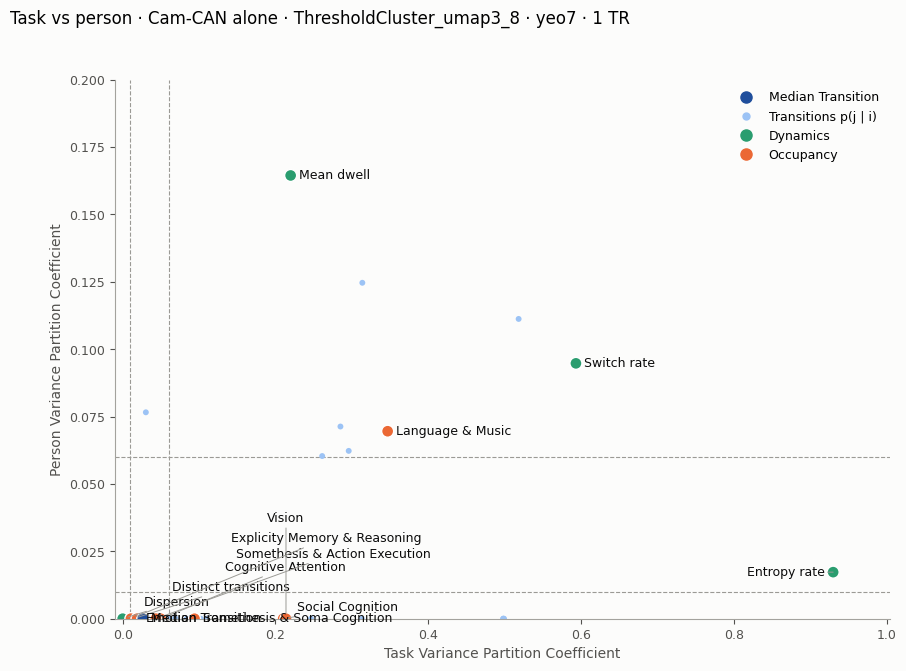

In [6]:
# Plot 5.0c
SAVE_AS = None    # None = "5_0c" -> notebooks/figures/05/5_0c.png; to keep another version: SAVE_AS = "5_0c_version2"
VPC_COHORT = "camcan"    # "camcan" | "hcp7t_fix" | "cneuromod" | ("ds002837": person and film confounded)
vp_c, vp_cells_c = ct.mixed_tables(co, fit_missing=False, only_cohort=VPC_COHORT)   # read, never refit here
cp.fig_task_person(co, vp_c, st_transitions=vp_cells_c, transitions=TRANSITIONS, guides=GUIDES, name=f"task_vs_person_{VPC_COHORT}",
                   title=f"Task vs person · {cp.cname(VPC_COHORT)} alone · {cp.ht.set_label(co.cfg.space)}");

### Extra: Figure 3 with the task share and its tiers (previous bottom right)

### Variance partition (one figure on its own, and the table for the text)

From the mixed model: the share of each property's **total** variance due to cohort (variance of the cohort means, the fixed effect), task, person and residual. Beside each bar, the VPC of the task **within cohorts** (Figure 3, bottom right: cohort out of the denominator).

In [7]:
# the mixed-model numbers: every property and every transition (transition structure included)
import pandas as pd
vt = cp.variance_table(co, vp, st_transitions=vp_cells)
with pd.option_context("display.max_rows", None):
    display(vt)
# print(vt.to_latex(index=False))


,family,property,σ² cohort,σ² task,σ² person,σ² residual,VPC task,VPC 95% CI,VPC person,R² marginal,R² conditional
0,transitions,Transition structure (fit to reference),0.703,0.013,0.100,0.153,0.049,0.026–0.090,0.376,0.725,0.842
1,dynamics,Distinct transitions,0.122,0.007,0.329,0.589,0.008,0.002–0.033,0.356,0.116,0.437
2,dynamics,Dispersion,0.111,0.016,0.263,0.619,0.018,0.007–0.050,0.293,0.110,0.387
3,dynamics,Mean dwell,0.297,0.028,0.231,0.407,0.041,0.020–0.083,0.347,0.309,0.577
4,dynamics,Entropy rate,0.779,0.015,0.064,0.090,0.090,0.051–0.152,0.376,0.822,0.905
5,dynamics,Switch rate,0.820,0.013,0.043,0.062,0.110,0.067–0.177,0.363,0.874,0.934
6,occupancy,Occupancy Cognitive Attention,0.245,0.021,0.276,0.482,0.027,0.001–0.336,0.355,0.239,0.530
7,occupancy,Occupancy Emotion,0.307,0.023,0.219,0.465,0.033,0.014–0.075,0.310,0.303,0.541
8,occupancy,Occupancy Language & Music,0.065,0.026,0.055,0.721,0.033,0.023–0.048,0.068,0.075,0.169
9,occupancy,Occupancy Somethesis & Soma Cognition,0.189,0.028,0.211,0.558,0.035,0.015–0.077,0.265,0.192,0.434


## Supplementary Figs. Sa–Sc

Sa–Sc: one row per task (rest, then every film, episode or run), grouped by cohort. Filled = the
same people did several tasks of their cohort (HCP, CNeuroMod, Cam-CAN); hollow = each film had its own
viewers (NNDb). Dashed blue = the global mean (every cohort and condition, each once). Occupancy
and transitions on 0–1; the dynamic metrics on the same fixed ranges as Figure 3.

#### Plot 5.1 — Supplementary Fig. Sa: dynamic metrics, task by task


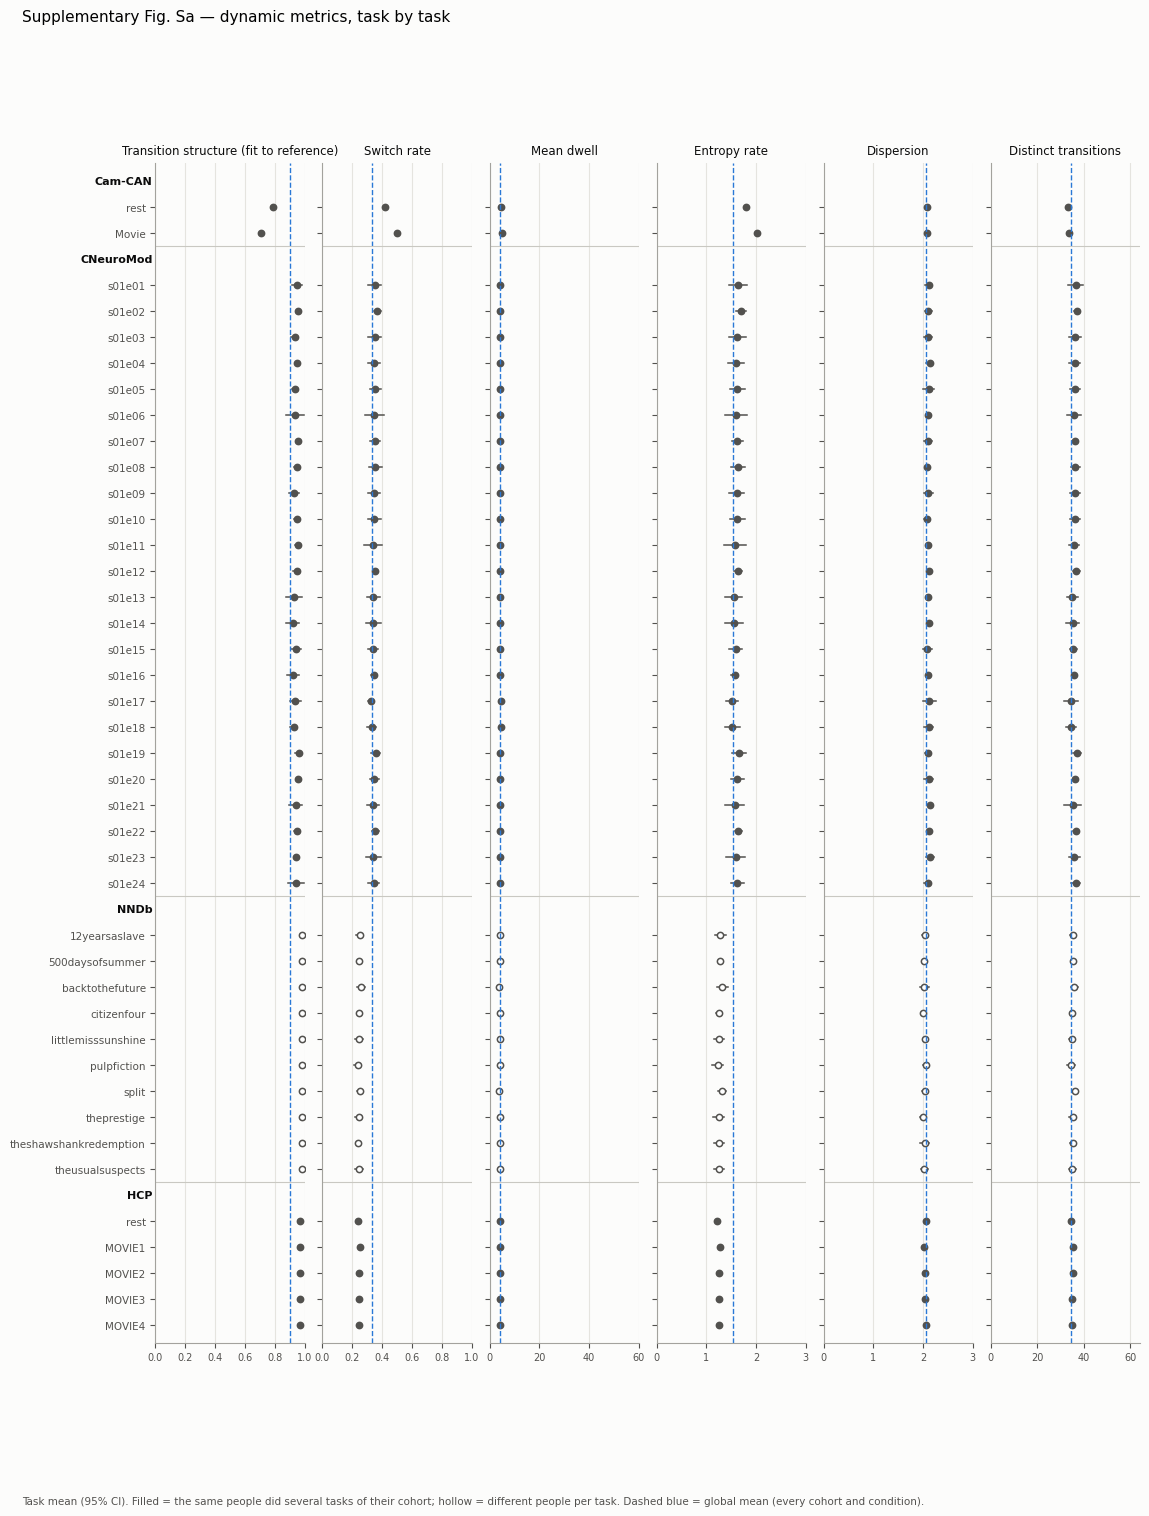

In [8]:
# Plot 5.1
SAVE_AS = None    # None = "5_1" -> notebooks/figures/05/5_1.png; to keep another version: SAVE_AS = "5_1_version2"
fs = co.film_summary(rest=True)
DYN = ["transition_fit", *co.dyn]
cp.fig_films_forest(co, fs, DYN, cp.global_means(co, DYN),
                    title="Supplementary Fig. Sa — dynamic metrics, task by task", name="Sa_films_dynamics");

#### Plot 5.2 — Supplementary Fig. Sb: occupancy, task by task


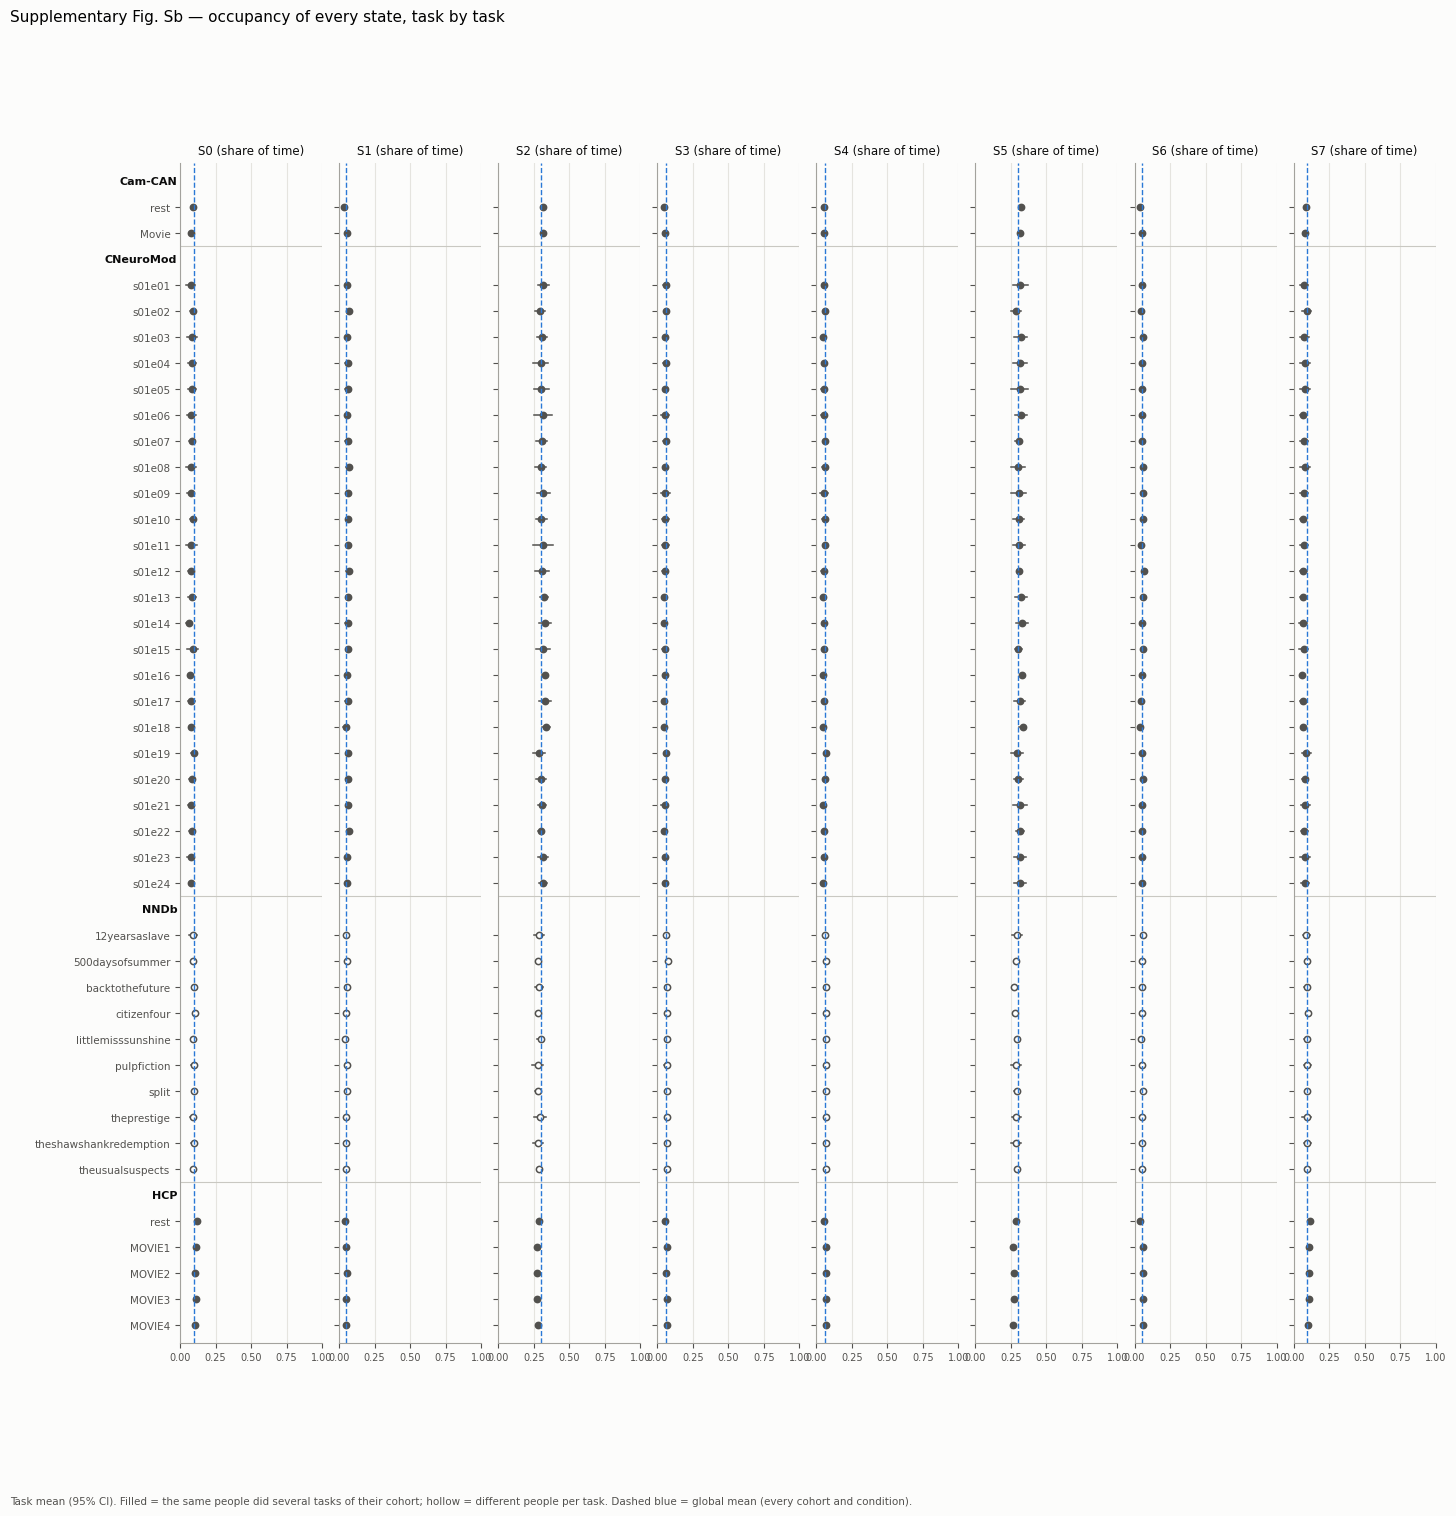

In [9]:
# Plot 5.2
SAVE_AS = None    # None = "5_2" -> notebooks/figures/05/5_2.png; to keep another version: SAVE_AS = "5_2_version2"
cp.fig_films_forest(co, fs, co.occ, cp.global_means(co, co.occ),
                    title="Supplementary Fig. Sb — occupancy of every state, task by task", name="Sb_films_occupancy",
                    labels={o: f"S{o[4:]} (share of time)" for o in co.occ});

#### Plot 5.3 — Supplementary Fig. Sc: transition matrices, task by task


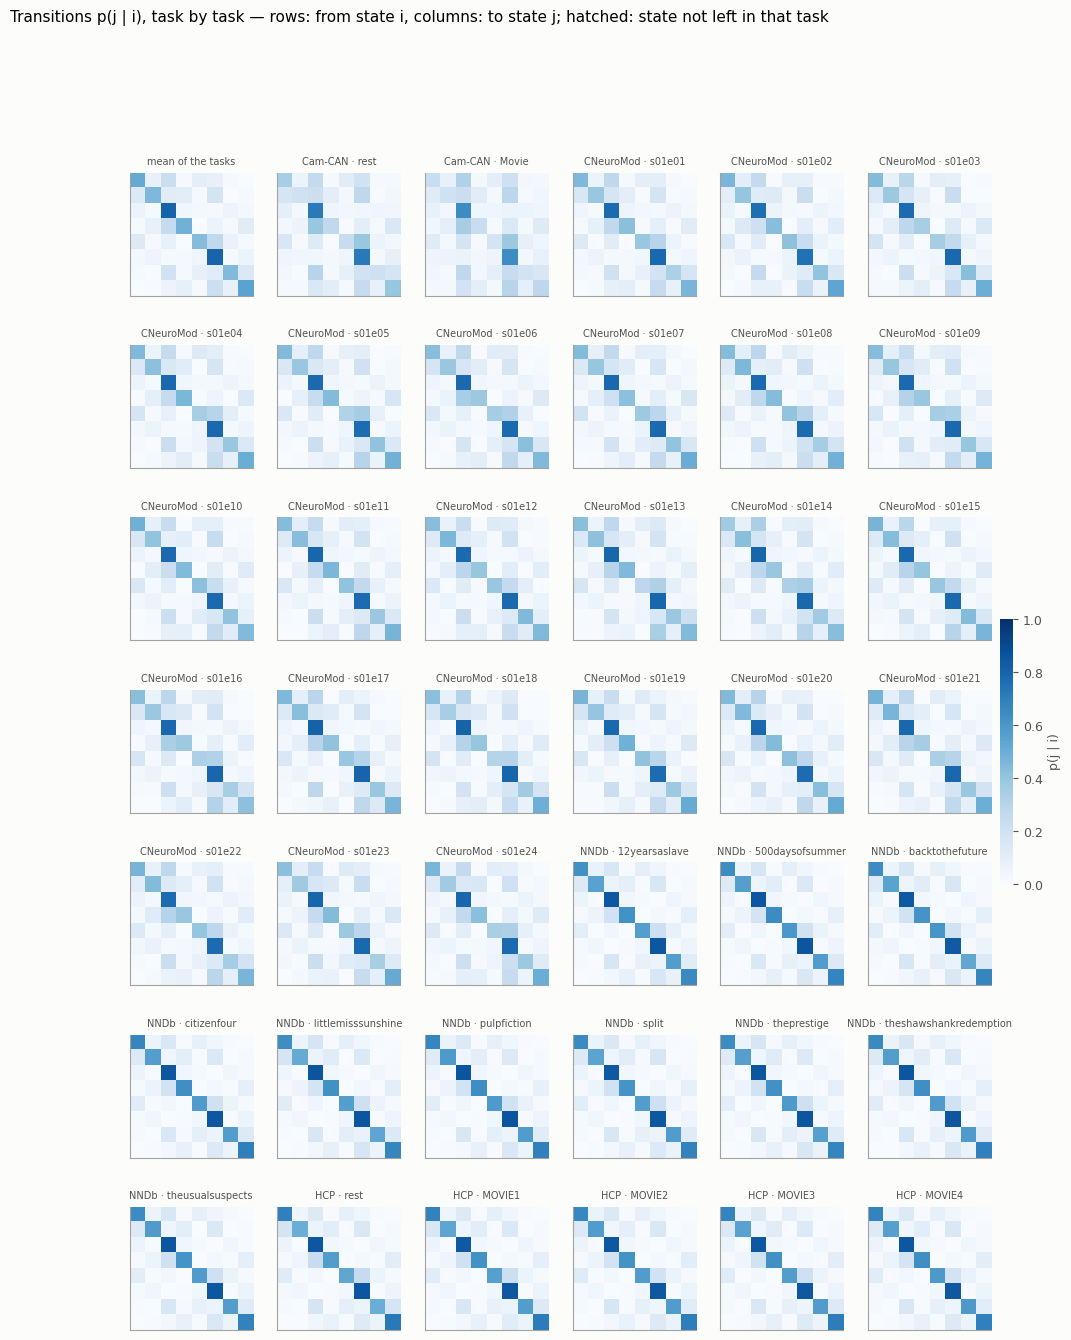

In [10]:
# Plot 5.3
SAVE_AS = None    # None = "5_3" -> notebooks/figures/05/5_3.png; to keep another version: SAVE_AS = "5_3_version2"
cp.fig_films_matrices(co, fs);

## Check: does a metric follow scan length?

Spearman ρ, within each cohort, between each metric and the minutes of scan behind it (one value per person and task). Entropy is corrected (Miller–Madow) and distinct transitions are rarefied to `co.distinct_minutes`; a metric still flagged here (|ρ| ≥ 0.3, FDR < 0.05) needs a correction too. Where films differ in length (NNDb), length and content go together: a flag, not a proof.

In [11]:
print(f"distinct transitions rarefied to {co.distinct_minutes} min")
dc = co.duration_check()
flag = dc[(dc.rho.abs() >= .3) & (dc.p_fdr < .05)]
display(dc.pivot_table(index="variable", columns=["cohort", "kind"], values="rho").round(2))
flag.round(3)

distinct transitions rarefied to 4.075500000000001 min


cohort                 camcan       cneuromod ds002837
kind                    movie  rest     movie    movie
variable                                              
dispersion              -0.36 -0.16     -0.24     0.04
entropy_rate_bits        0.36  0.41      0.26    -0.03
mean_dwell_s            -0.05  0.07     -0.17     0.05
n_distinct_transitions   0.33  0.39      0.22    -0.04
occ_0                    0.10  0.19      0.06     0.20
occ_1                    0.14  0.02      0.05    -0.03
occ_2                   -0.18 -0.24     -0.13    -0.09
occ_3                    0.10  0.23      0.20    -0.17
occ_4                    0.15  0.15      0.09    -0.08
occ_5                   -0.24 -0.37     -0.11    -0.05
occ_6                    0.04  0.03     -0.01     0.01
occ_7                    0.21  0.33      0.05     0.13
switch_rate              0.26  0.31      0.27    -0.05

,cohort,kind,variable,n,minutes_min,minutes_max,rho,p,p_fdr
2,camcan,movie,entropy_rate_bits,622,4.076,7.945,0.356,0.0,0.0
3,camcan,movie,dispersion,622,4.076,7.945,-0.363,0.0,0.0
4,camcan,movie,n_distinct_transitions,622,4.076,7.945,0.332,0.0,0.0
13,camcan,rest,switch_rate,540,4.301,8.570,0.306,0.0,0.0
15,camcan,rest,entropy_rate_bits,540,4.301,8.570,0.408,0.0,0.0
17,camcan,rest,n_distinct_transitions,540,4.301,8.570,0.387,0.0,0.0
23,camcan,rest,occ_5,540,4.301,8.570,-0.370,0.0,0.0
25,camcan,rest,occ_7,540,4.301,8.570,0.326,0.0,0.0


## Numbers for the text

ω² of task per property (Figure 3, bottom right), and, task by task, how many task × property
comparisons differ from the other tasks of their cohort (Supplementary Sa–Sc, BH-FDR).

In [12]:
display(st[["variable", "task_d", "task_lo", "task_hi", "tier", "task_p_tier", "task_mean_lo", "task_mean_hi", "n_tasks"]]
        .rename(columns={"task_d": "omega2", "task_lo": "lo", "task_hi": "hi", "task_p_tier": "P_tier"}).round(3))
fs.groupby(fs["variable"].map(lambda v: "transition" if "->" in v or v == "transition_fit" else
                              "occupancy" if v.startswith("occ_") else "dynamics"))["differs"].agg(["sum", "count"])


,variable,omega2,lo,hi,tier,P_tier,task_mean_lo,task_mean_hi,n_tasks
0,transition_fit,0.045,-0.078,0.167,moderate,0.307,0.710,0.985,41
1,occupancy_fit,0.011,-0.018,0.040,moderate,0.526,0.969,0.997,41
2,switch_rate,0.071,-0.191,0.332,context-dependent,0.532,0.236,0.502,41
3,mean_dwell_s,-0.003,-0.094,0.088,stable,0.610,3.920,4.851,41
4,entropy_rate_bits,0.062,-0.124,0.249,context-dependent,0.510,1.218,2.019,41
5,dispersion,0.007,-0.025,0.039,stable,0.565,2.006,2.144,41
6,n_distinct_transitions,0.011,-0.021,0.043,moderate,0.532,33.347,37.078,41
7,occ_0,0.029,-0.046,0.104,moderate,0.482,0.063,0.119,41
8,occ_1,0.120,0.039,0.200,context-dependent,0.927,0.034,0.072,41
9,occ_2,0.005,-0.009,0.020,stable,0.746,0.272,0.335,41


,sum,count
variable,,
dynamics,18,205
occupancy,40,328
transition,270,2665
